In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

In [5]:
test_loan_data = pd.read_csv('/content/test.csv')
train_loan_data = pd.read_csv('/content/train.csv')

In [6]:
train_loan_data.shape

(614, 13)

In [7]:
train_loan_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [8]:
train_loan_data.dtypes

,0
Loan_ID,object
Gender,object
Married,object
Dependents,object
Education,object
Self_Employed,object
ApplicantIncome,int64
CoapplicantIncome,float64
LoanAmount,float64
Loan_Amount_Term,float64


In [9]:
train_loan_data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [10]:
test_loan_data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area'],
      dtype='object')

In [11]:
train_loan_data.head(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [12]:
train_loan_data.tail(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [13]:
train_loan_data.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [14]:
x_data = train_loan_data.drop('LoanAmount', axis='columns')

In [15]:
y_data = train_loan_data['LoanAmount']

<Axes: xlabel='LoanAmount', ylabel='Density'>

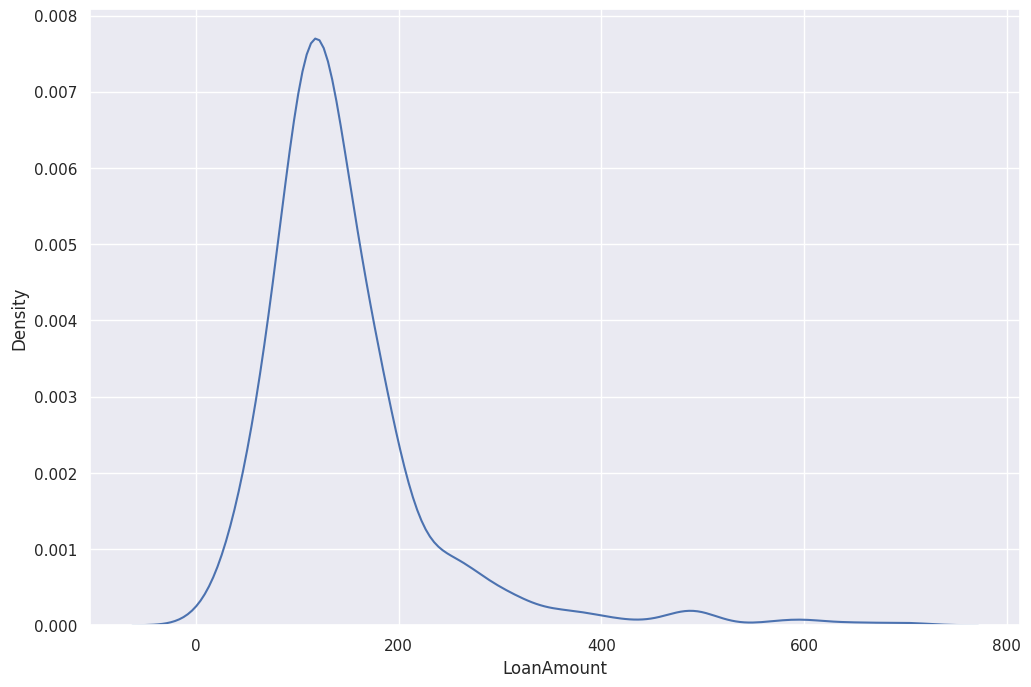

In [16]:
plt.figure(figsize=(12,8))
sns.set(style='darkgrid')
sns.kdeplot(y_data)

<Axes: ylabel='LoanAmount'>

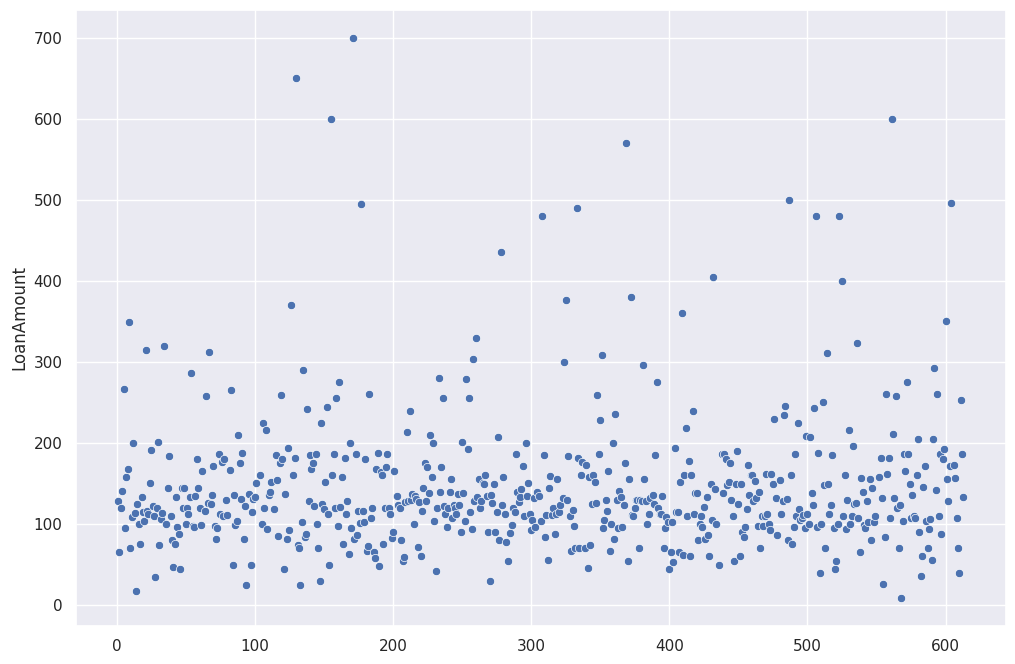

In [17]:
plt.figure(figsize=(12,8))
sns.scatterplot(data=y_data)

<Axes: >

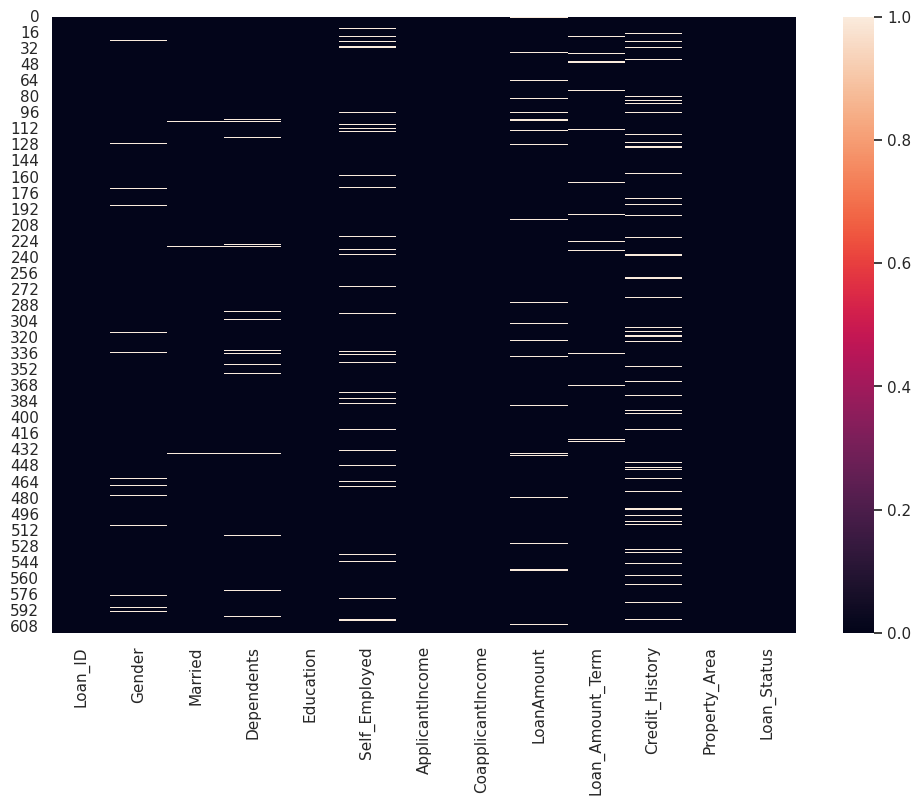

In [18]:
plt.figure(figsize=(12,8))
sns.heatmap(train_loan_data.isnull())

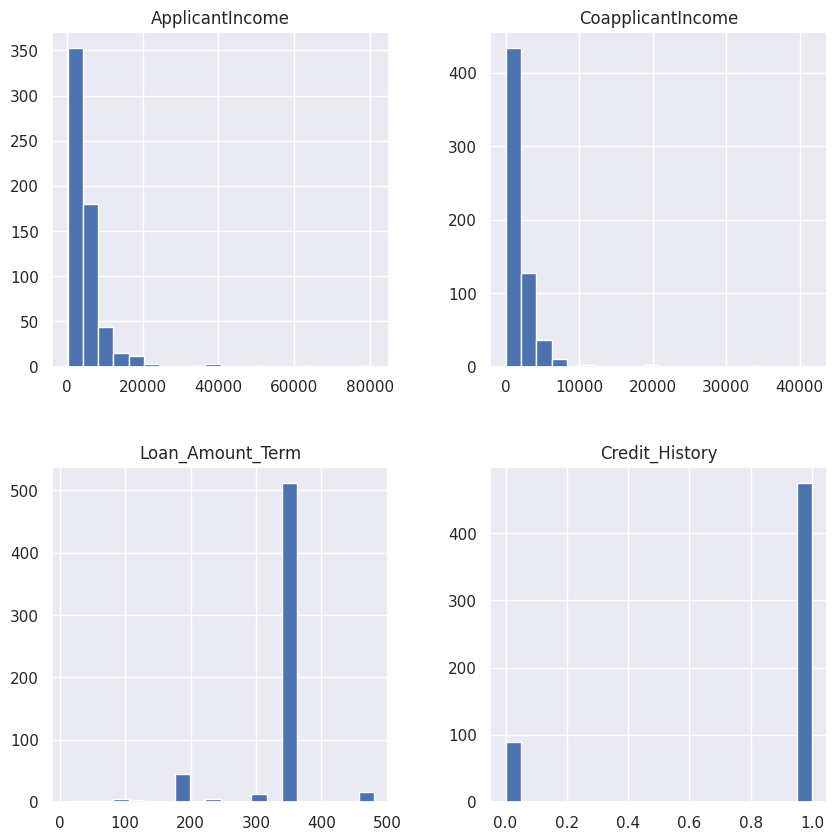

In [19]:
x_data.hist(figsize = (10, 10), bins = 20, legend = False)
plt.show()

<Axes: ylabel='count'>

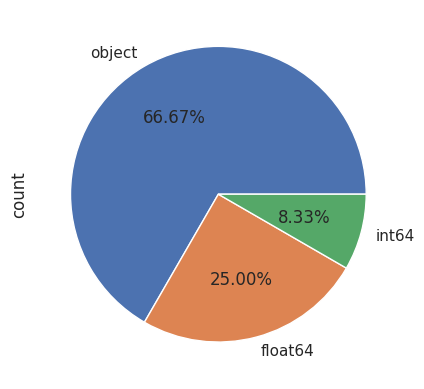

In [20]:
x_data.dtypes.value_counts().plot.pie(autopct='%0.2f%%')

In [21]:
obj_col = x_data.select_dtypes(include='object').columns
int_col = x_data.select_dtypes(include='int').columns
flt_col = x_data.select_dtypes(include='float').columns

In [22]:
le = LabelEncoder()

In [23]:
for obj in obj_col:
    x_data[obj] = le.fit_transform(x_data[obj].astype(str))

In [24]:
for nt in int_col:
    x_data[nt] = le.fit_transform(x_data[nt].astype(int))

In [25]:
for flt in flt_col:
    x_data[flt] = le.fit_transform(x_data[flt].astype(float))

In [26]:
x_data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,0,1,0,0,0,0,376,0,8,1,2,1
1,1,1,1,1,0,0,306,60,8,1,0,0
2,2,1,1,0,0,1,139,0,8,1,2,1
3,3,1,1,0,1,0,90,160,8,1,2,1
4,4,1,0,0,0,0,381,0,8,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...
609,609,0,0,0,0,0,125,0,8,1,0,1
610,610,1,1,3,0,0,275,0,5,1,0,1
611,611,1,1,1,0,0,431,3,8,1,2,1
612,612,1,1,2,0,0,422,0,8,1,2,1


<Axes: ylabel='count'>

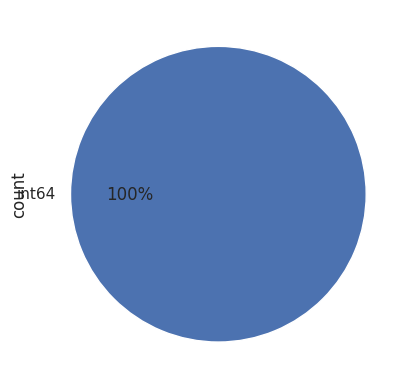

In [27]:
x_data.dtypes.value_counts().plot.pie(autopct='%2.0f%%')

In [28]:
x_data = x_data.dropna()
y_data = y_data.dropna()

In [29]:
x_data = x_data.drop([5,6,1,4,7])

<Axes: >

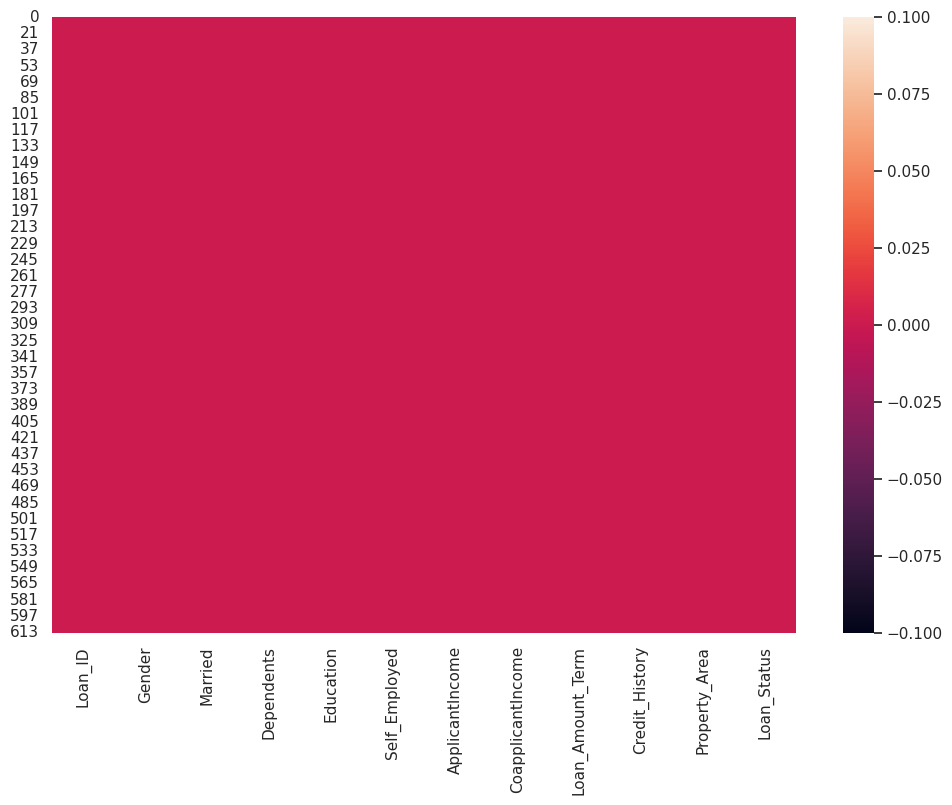

In [30]:
plt.figure(figsize=(12,8))
sns.heatmap(x_data.isnull())

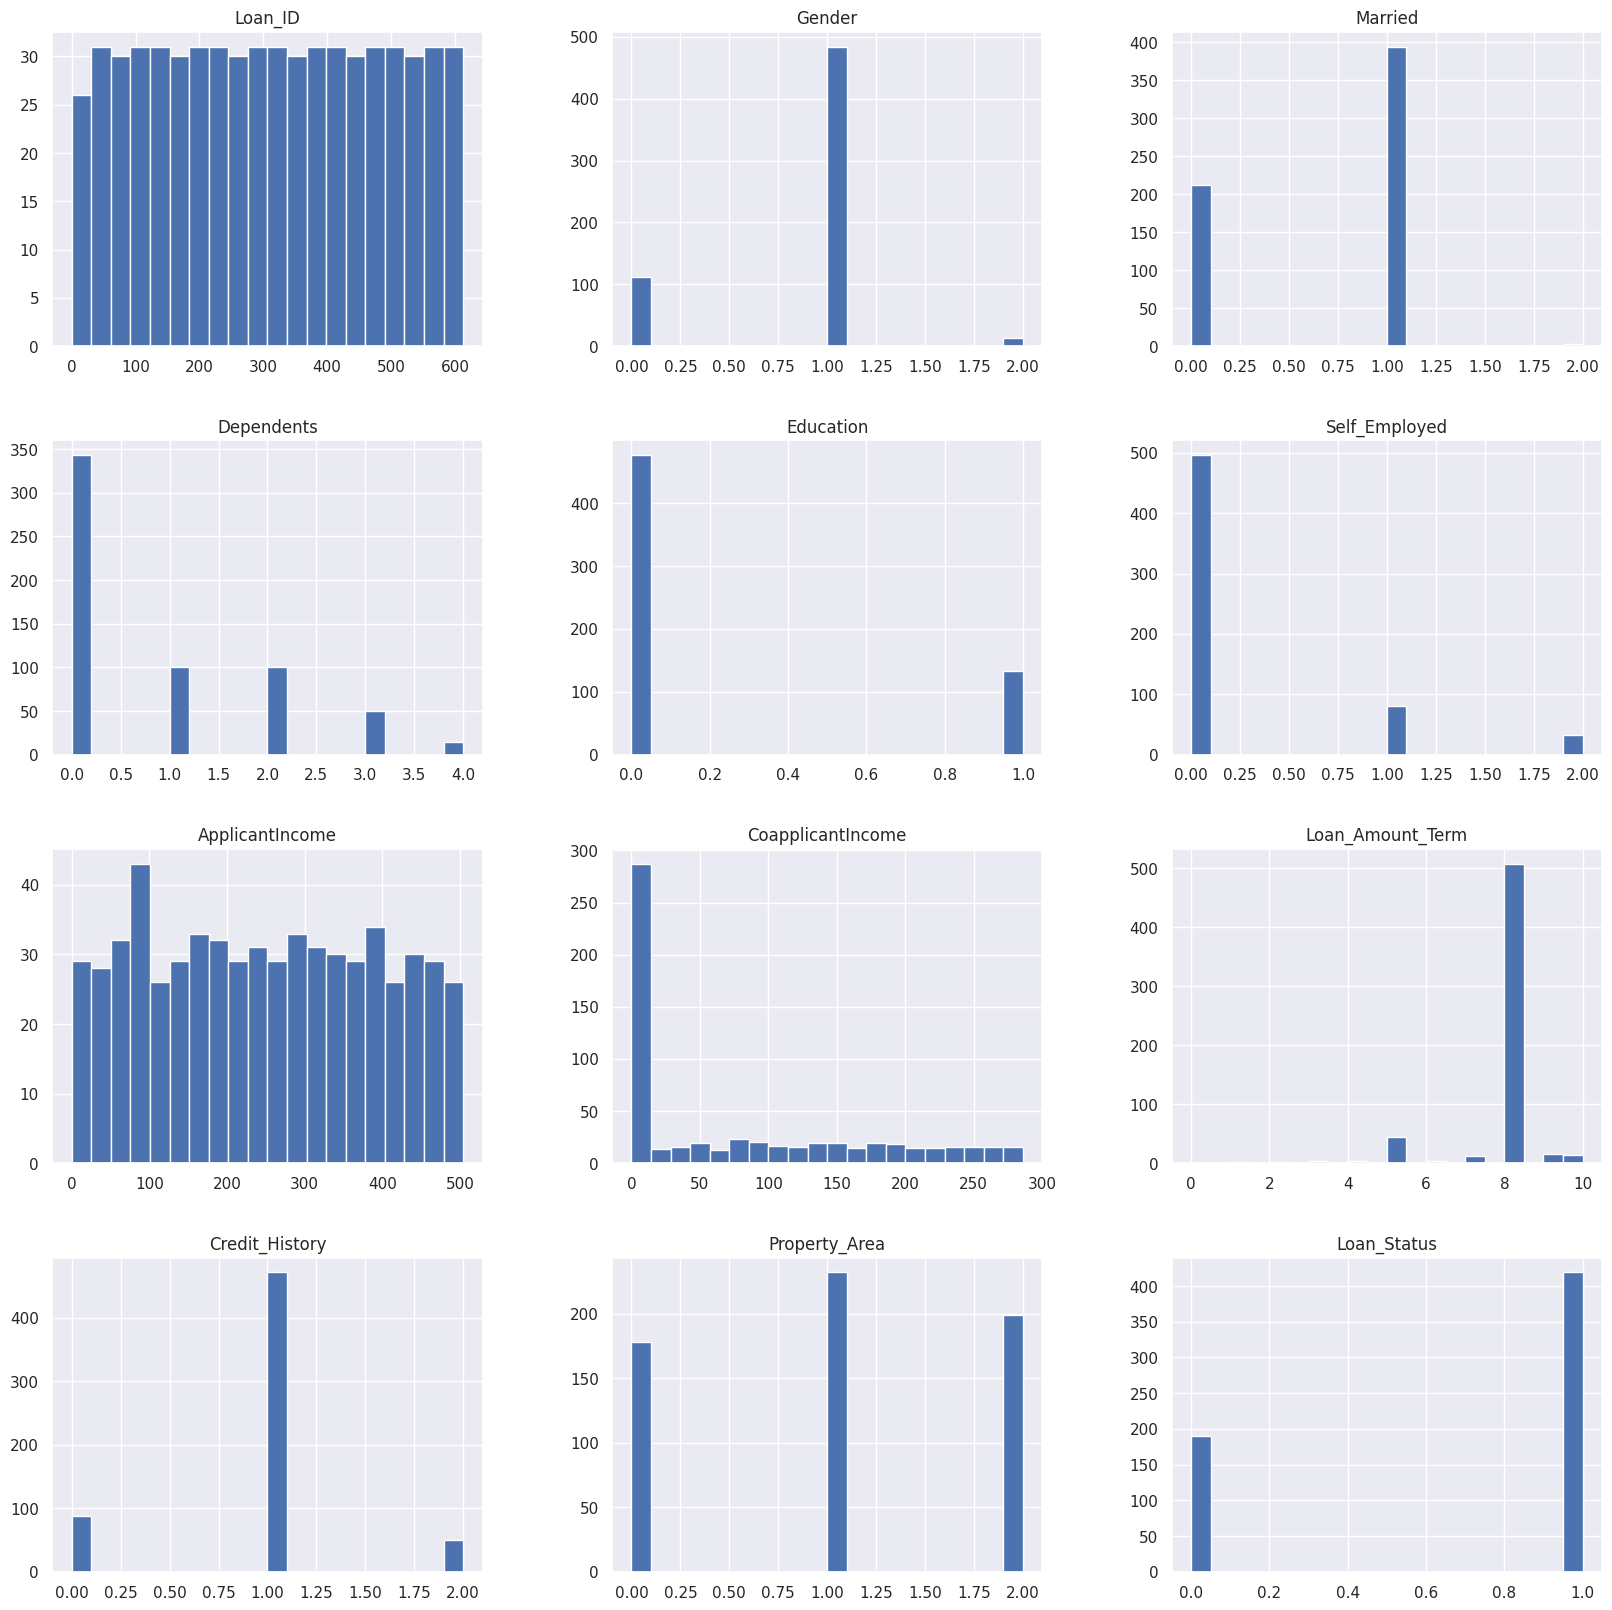

In [31]:
x_data.hist(figsize = (20, 20), bins = 20, legend = False)
plt.show()

In [32]:
x_data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

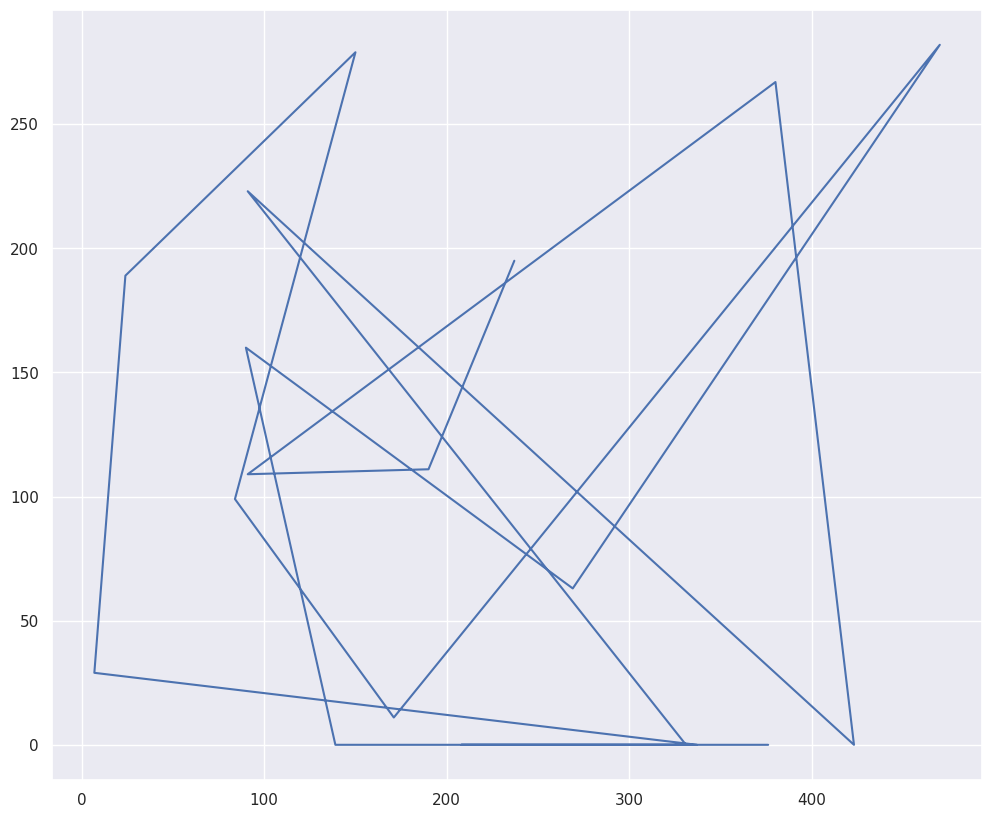

In [33]:
plt.figure(figsize=(12,10))
plt.plot(x_data['ApplicantIncome'][0:20], x_data['CoapplicantIncome'][0:20])
plt.show()

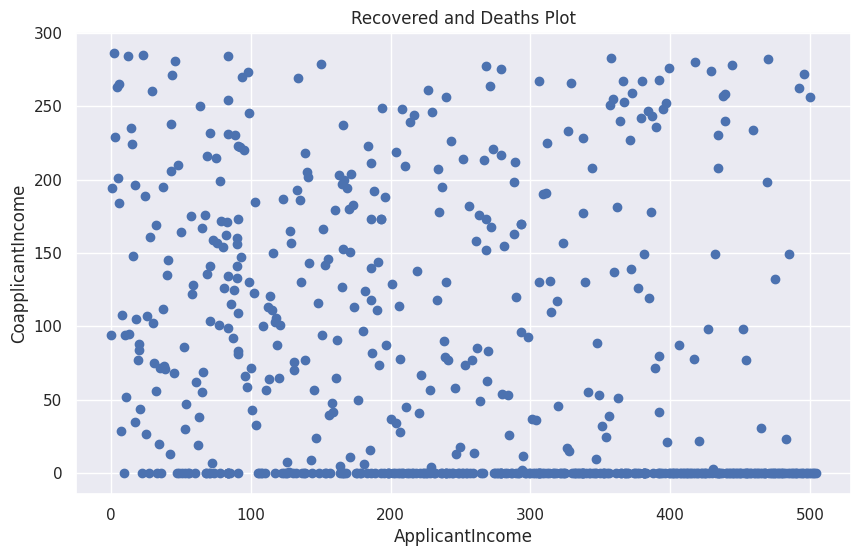

In [34]:
plt.figure(figsize=(10, 6))
plt.plot(x_data['ApplicantIncome'], x_data['CoapplicantIncome'], 'o')
plt.title("Recovered and Deaths Plot")
plt.xlabel("ApplicantIncome")
plt.ylabel("CoapplicantIncome")
plt.show()

In [36]:
# Align x_data and y_data by their common index first
common_index = x_data.index.intersection(y_data.index)
x_data_aligned = x_data.loc[common_index]
y_data_aligned = y_data.loc[common_index]

# Perform the train-test split
x_train, x_test, y_train, y_test = train_test_split(x_data_aligned, y_data_aligned, test_size=0.1)

In [37]:
rmr = RandomForestRegressor()

In [38]:
x_test

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
557,557,1,1,3,0,1,456,0,8,1,1,1
239,239,1,1,1,0,0,183,0,8,1,1,1
225,225,1,1,0,0,0,178,0,8,1,0,0
76,76,1,0,0,0,0,240,256,8,1,2,0
311,311,1,0,0,1,0,128,165,8,1,1,1
90,90,1,1,0,0,0,133,193,8,1,1,1
84,84,1,1,1,0,0,265,0,6,1,2,1
501,501,0,0,0,0,0,164,0,8,1,1,1
397,397,1,1,0,0,0,145,57,8,1,2,1
578,578,1,1,1,0,0,16,148,8,1,0,1


In [39]:
rmr.fit(x_train, y_train)

RandomForestRegressor()

In [40]:
rmr.predict(x_test)

array([230.63, 101.35,  78.39, 172.33, 121.91, 136.6 ,  98.93,  78.02,
       109.44, 124.98, 102.31, 150.89, 164.81, 226.  ,  99.  , 117.3 ,
       200.22, 145.52, 132.44,  86.63, 144.08, 154.88, 130.76,  99.7 ,
       174.53,  99.26,  98.14, 180.72, 120.8 , 129.57, 166.25, 129.13,
       183.91, 301.44, 266.6 , 107.42, 165.41,  83.59, 143.36, 361.8 ,
       116.07,  73.39, 205.1 , 325.03, 222.06, 105.49, 168.16,  95.96,
       284.64, 142.72, 103.85, 121.92, 150.1 , 109.26, 122.31,  85.95,
       131.75, 226.8 ,  77.36])

In [41]:
test_loan_data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban
...,...,...,...,...,...,...,...,...,...,...,...,...
362,LP002971,Male,Yes,3+,Not Graduate,Yes,4009,1777,113.0,360.0,1.0,Urban
363,LP002975,Male,Yes,0,Graduate,No,4158,709,115.0,360.0,1.0,Urban
364,LP002980,Male,No,0,Graduate,No,3250,1993,126.0,360.0,NaN,Semiurban
365,LP002986,Male,Yes,0,Graduate,No,5000,2393,158.0,360.0,1.0,Rural
